# NIST TN 1822 — Verif.3.1: Exit route allocation

NIST TN 1822 Figure 8: 12 rooms around a 1 m corridor, main exit at the top and a secondary exit on the right. Rooms 1,2,3,4,7,8,9,10 are allocated to the main exit; rooms 5,6,11,12 to the secondary exit.

Helpers (`agent_to_distribution`, `agent_to_actual_exit`) are reused from the canonical rimea10 notebook.

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 17:32 CEST


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pedpy
from shapely.geometry import Point, Polygon

from jupedsim_scenarios import load_scenario, run_scenario

In [3]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#f7f7f5",
    "axes.edgecolor": "#3a3a3a",
    "axes.labelcolor": "#1d1d1d",
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "figure.figsize": (8, 5),
})

In [4]:
import numpy as np

# House style for the V&V figures (plain matplotlib; applied per figure via rc_context).
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, PathPatch
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.path import Path as MplPath

VV_BLUE, VV_ORANGE, VV_RED, VV_GREEN = "#0072B2", "#E69F00", "#D55E00", "#009E73"
VV_RC = {
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 150,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "lightgrey", "axes.labelcolor": "dimgrey",
    "axes.titlecolor": "#333333", "axes.titleweight": "normal", "axes.titlesize": 11,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": "dimgrey", "ytick.color": "dimgrey",
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": True, "legend.facecolor": "white", "legend.framealpha": 0.8,
    "legend.edgecolor": "lightgrey", "legend.labelcolor": "dimgrey", "legend.fontsize": 9,
}


def vv_polygon_patch(geom, **kwargs):
    """Matplotlib patch for a shapely (Multi)Polygon, holes included."""
    verts, codes = [], []
    for part in getattr(geom, "geoms", [geom]):
        for ring in [part.exterior, *part.interiors]:
            xy = np.asarray(ring.coords)
            verts.extend(xy)
            codes += [MplPath.MOVETO] + [MplPath.LINETO] * (len(xy) - 2) + [MplPath.CLOSEPOLY]
    return PathPatch(MplPath(verts, codes), **kwargs)


def vv_draw_scenario(ax, scenario, starts=True, pad=0.04):
    """Draw walkable area, exits and start areas of a loaded scenario; return legend handles."""
    ax.add_patch(vv_polygon_patch(scenario.walkable_polygon, facecolor="#eeeeee",
                                  edgecolor="dimgrey", linewidth=1.4, zorder=1))
    handles = [Patch(facecolor="#eeeeee", edgecolor="dimgrey", label="walkable area")]
    if starts:
        for dist in scenario.distributions.values():
            ax.add_patch(MplPolygon(dist["coordinates"], closed=True,
                                    facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                                    linestyle="--", linewidth=1.2, hatch="..", zorder=2))
        handles.append(Patch(facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                             linestyle="--", hatch="..", label="start area"))
    for ex in scenario.exits.values():
        ax.add_patch(MplPolygon(ex["coordinates"], closed=True,
                                facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                                linewidth=1.2, hatch="///", zorder=3))
    if scenario.exits:
        handles.append(Patch(facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                             hatch="///", label="exit"))
    minx, miny, maxx, maxy = scenario.walkable_polygon.bounds
    m = pad * max(maxx - minx, maxy - miny)
    ax.set_xlim(minx - m, maxx + m)
    ax.set_ylim(miny - m, maxy + m)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    return handles


def vv_agent_count(scenario):
    """Total number of agents placed by the scenario's start areas."""
    return sum(int(d.get("parameters", {}).get("number", 0)) for d in scenario.distributions.values())

## Load the scenario and the encoded route allocation

In [5]:
SCENARIO_ZIP = Path("scenario_files") / "Nist-3-1-route-allocation.zip"
scenario = load_scenario(str(SCENARIO_ZIP))
print(scenario.summary())
# Resolve allocated-exit map from whichever journey schema the ZIP carries.
raw = scenario.raw
if 'journeys' in raw:
    journey_map = {j['stages'][0]: j['stages'][-1] for j in raw['journeys']}
else:
    j_to_exit = {j['id']: j['sequence'][-1] for j in raw.get('journeys_v2', [])}
    journey_map = {did: j_to_exit.get((d.get('journey_weights') or [{}])[0].get('journey_id'), '')
                   for did, d in scenario.distributions.items()}
print('expected assignment:', journey_map)

Scenario: scenario_files/Nist-3-1-route-allocation.zip
  Model:         CollisionFreeSpeedModel
  Seed:          420
  Max time:      300s
  Exits:         2
  Distributions: 12
  Stages:        0
  Zones:         0
  Journeys:      0
  Agents:        ~23
    jps-distributions_0: 2 agents
    jps-distributions_1: 2 agents
    jps-distributions_2: 2 agents
    jps-distributions_3: 2 agents
    jps-distributions_4: 2 agents
    jps-distributions_5: 2 agents
    jps-distributions_6: 2 agents
    jps-distributions_7: 1 agents
    jps-distributions_8: 2 agents
    jps-distributions_9: 2 agents
    jps-distributions_10: 2 agents
    jps-distributions_11: 2 agents
expected assignment: {'jps-distributions_0': 'jps-exits_0', 'jps-distributions_1': 'jps-exits_0', 'jps-distributions_2': 'jps-exits_0', 'jps-distributions_3': 'jps-exits_0', 'jps-distributions_4': 'jps-exits_0', 'jps-distributions_5': 'jps-exits_0', 'jps-distributions_6': 'jps-exits_0', 'jps-distributions_7': 'jps-exits_0', 'jps-dis

## Scenario figure

Rooms and exits from the loaded scenario; each room is coloured by the exit its journey assigns.

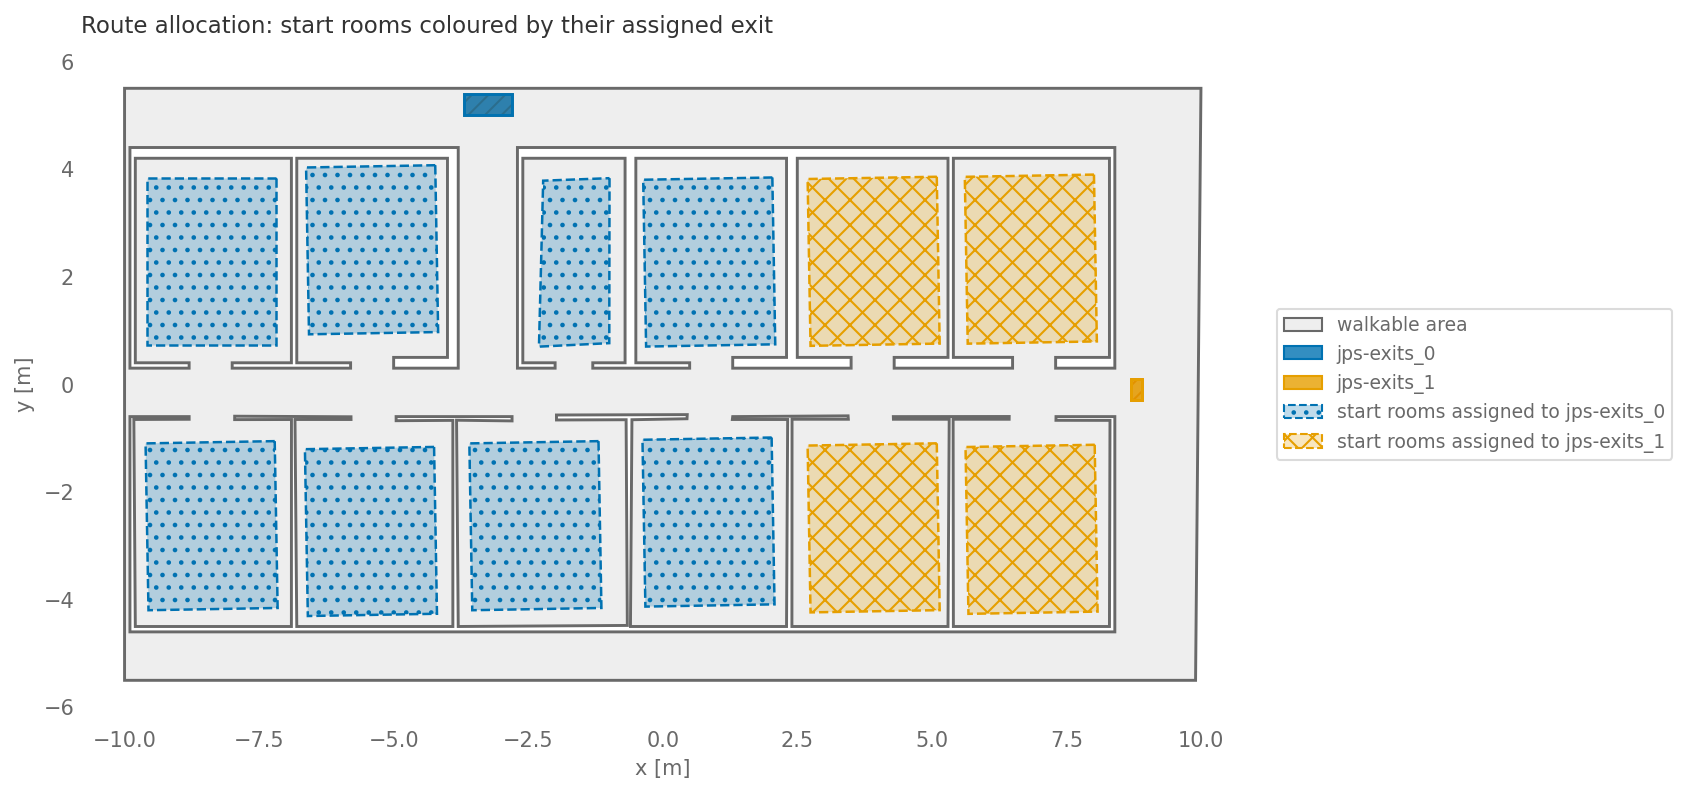

In [6]:
# Start areas coloured by the exit that the scenario journey assigns to them.
exit_ids = sorted(scenario.exits)
palette = dict(zip(exit_ids, [VV_BLUE, VV_ORANGE]))
hatches = dict(zip(exit_ids, ["..", "xx"]))
names = {}
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(10, 6))
    handles = vv_draw_scenario(ax, scenario, starts=False)
    handles = handles[:1]
    for dist_id, dist in scenario.distributions.items():
        target = journey_map[dist_id]
        ax.add_patch(MplPolygon(dist["coordinates"], closed=True, facecolor=to_rgba(palette[target], 0.25),
                                edgecolor=palette[target], linestyle="--", linewidth=1.2,
                                hatch=hatches[target], zorder=2))
    for ex_id, ex in scenario.exits.items():
        ax.add_patch(MplPolygon(ex["coordinates"], closed=True, facecolor=to_rgba(palette.get(ex_id, VV_RED), 0.8),
                                edgecolor=palette.get(ex_id, VV_RED), linewidth=1.4, zorder=3))
    for t in exit_ids:
        handles.append(Patch(facecolor=to_rgba(palette[t], 0.8), edgecolor=palette[t], label=names.get(t, t)))
    for t in sorted(set(journey_map.values())):
        handles.append(Patch(facecolor=to_rgba(palette[t], 0.25), edgecolor=palette[t], linestyle="--",
                             hatch=hatches[t], label=f"start rooms assigned to {names.get(t, t)}"))
    ax.set_title("Route allocation: start rooms coloured by their assigned exit", loc="left")
    ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.02, 0.5))
    plt.show()

## Helper functions (from rimea10_route_allocation.ipynb)

In [7]:
def agent_to_distribution(trajectory, distributions):
    first = trajectory.data.sort_values(['id', 'frame']).groupby('id').first().reset_index()
    polys = {k: Polygon(v['coordinates']) for k, v in distributions.items()}
    mapping = {}
    for row in first.itertuples():
        point = Point(row.x, row.y)
        for did, poly in polys.items():
            if poly.covers(point):
                mapping[row.id] = did
                break
    return mapping

def agent_to_actual_exit(trajectory, exits):
    last = trajectory.data.sort_values(['id', 'frame']).groupby('id').last().reset_index()
    polys = {k: Polygon(v['coordinates']) for k, v in exits.items()}
    return {
        row.id: min(polys, key=lambda eid: polys[eid].distance(Point(row.x, row.y)))
        for row in last.itertuples()
    }

## Run the scenario

In [8]:
result = run_scenario(scenario, seed=42)
trajectory = pedpy.TrajectoryData(
    result.trajectory_dataframe()[['id', 'frame', 'x', 'y']].copy(),
    frame_rate=result.frame_rate,
)

## Map each agent to expected vs actual exit

In [9]:
homes = agent_to_distribution(trajectory, scenario.distributions)
actuals = agent_to_actual_exit(trajectory, scenario.exits)
rows = [
    {'agent': int(aid), 'home': homes.get(aid),
     'expected_exit': journey_map.get(homes.get(aid)),
     'actual_exit': actuals[aid]}
    for aid in actuals
]
assignment = pd.DataFrame(rows)
assignment['matches'] = assignment['expected_exit'] == assignment['actual_exit']
assignment

,agent,home,expected_exit,actual_exit,matches
0,1,jps-distributions_0,jps-exits_0,jps-exits_0,True
1,2,jps-distributions_0,jps-exits_0,jps-exits_0,True
2,3,jps-distributions_1,jps-exits_0,jps-exits_0,True
3,4,jps-distributions_1,jps-exits_0,jps-exits_0,True
4,5,jps-distributions_2,jps-exits_0,jps-exits_0,True
...,...,...,...,...,...
18,19,jps-distributions_9,jps-exits_1,jps-exits_1,True
19,20,jps-distributions_10,jps-exits_1,jps-exits_1,True
20,21,jps-distributions_10,jps-exits_1,jps-exits_1,True
21,22,jps-distributions_11,jps-exits_1,jps-exits_1,True


## Plot trajectories coloured by allocated exit

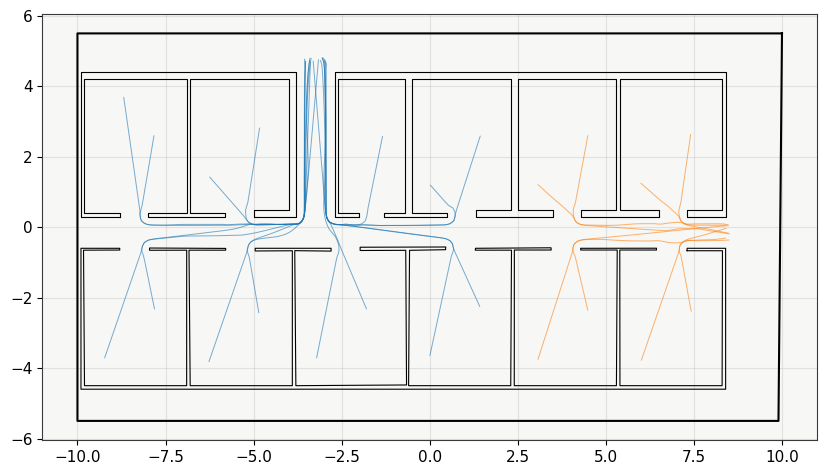

In [10]:
fig, ax = plt.subplots(figsize=(10, 7))
x, y = scenario.walkable_polygon.exterior.xy
ax.plot(x, y, 'k-')
for interior in scenario.walkable_polygon.interiors:
    ix, iy = interior.xy
    ax.plot(ix, iy, 'k-', lw=0.8)
colors = {'jps-exits_0': 'tab:blue', 'jps-exits_1': 'tab:orange'}
df = trajectory.data
for agent_id, sub in df.sort_values('frame').groupby('id'):
    row = assignment[assignment.agent == agent_id]
    if len(row) == 0:
        continue
    ax.plot(sub.x, sub.y, color=colors.get(row.iloc[0].expected_exit, 'k'),
            alpha=0.6, lw=0.7)
ax.set_aspect('equal')
plt.show()

## Result figure

Number of agents that reached the exit allocated to their start room. Acceptance: every agent.

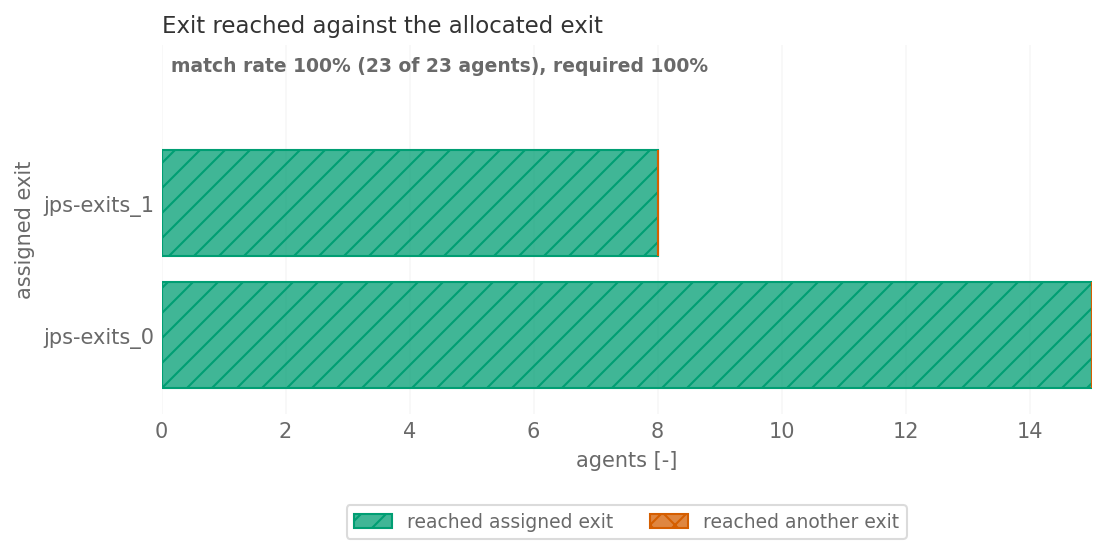

In [11]:
# Agents per assigned exit: how many reached the exit that their route allocates.
tab = assignment.groupby("expected_exit")["matches"].agg(["sum", "count"])
tab["wrong"] = tab["count"] - tab["sum"]
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(8, 1.6 + 0.8 * len(tab)))
    y = np.arange(len(tab))
    ax.barh(y, tab["sum"], color=to_rgba(VV_GREEN, 0.75), edgecolor=VV_GREEN, hatch="//", label="reached assigned exit")
    ax.barh(y, tab["wrong"], left=tab["sum"], color=to_rgba(VV_RED, 0.75), edgecolor=VV_RED, hatch="xx",
            label="reached another exit")
    ax.set_yticks(y, [str(e) for e in tab.index])
    ax.set_ylim(-0.6, len(tab) - 0.5 + 0.7)
    ax.set_xlabel("agents [-]")
    ax.set_ylabel("assigned exit")
    rate = tab["sum"].sum() / tab["count"].sum()
    ax.set_title("Exit reached against the allocated exit", loc="left")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
    ax.text(0.01, 0.97, f"match rate {rate:.0%} ({int(tab['sum'].sum())} of {int(tab['count'].sum())} agents), required 100%",
            transform=ax.transAxes, ha="left", va="top", color="dimgrey", fontweight="semibold", fontsize=9)
    ax.grid(axis="y", visible=False)
    plt.show()

## Acceptance

In [12]:
match_rate = assignment['matches'].mean()
print(f'allocation match rate: {match_rate:.1%}')
assert match_rate == 1.0, assignment[~assignment['matches']]
result.cleanup()

allocation match rate: 100.0%


1